# 03 · Attention from scratch

**Goal:** derive self-attention instead of being handed the formula. We start
with "average the past tokens", make the average weighted, then make the
weights *data-dependent* — which is attention.

**You will be able to:**
1. explain why the causal average can be written as a matrix multiply
2. say what each of query, key and value is for, in one sentence each
3. write scaled dot-product attention from memory, with correct shapes
4. justify the `1/sqrt(d)` scaling and the `-inf` mask numerically
5. read an attention heatmap

Prerequisites: notebooks 01–02.

In [1]:
import math
import sys
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F

ROOT = Path.cwd()
if not (ROOT / "course_utils.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import course_utils as cu

cu.set_seed(1337)
torch.set_printoptions(precision=3, sci_mode=False, linewidth=120)

## 1 · The problem, restated

The bigram model predicts from one token. We want each position `t` to build a
representation from **all** positions `<= t`. Two hard constraints:

- **Causality.** Position `t` may never see `t+1`; otherwise the model cheats
  at training time and is useless at generation time.
- **Variable, learned relevance.** Which earlier tokens matter depends on the
  content, not just the distance. A verb needs its subject, wherever it sits.

Start with the crudest version that satisfies causality: average everything
up to and including `t`.

In [2]:
B, T, C = 1, 5, 2                       # 1 sequence, 5 positions, 2 channels
x = torch.arange(1.0, T * C + 1).view(B, T, C)
print("x =\n", x[0])

# Version 1: explicit loops. Correct, and hopelessly slow.
out_loop = torch.zeros(B, T, C)
for b in range(B):
    for t in range(T):
        out_loop[b, t] = x[b, :t + 1].mean(dim=0)     # mean over the past
print("\ncausal running mean =\n", out_loop[0])

x =
 tensor([[ 1.,  2.],
        [ 3.,  4.],
        [ 5.,  6.],
        [ 7.,  8.],
        [ 9., 10.]])

causal running mean =
 tensor([[1., 2.],
        [2., 3.],
        [3., 4.],
        [4., 5.],
        [5., 6.]])


## 2 · The matrix trick

A weighted sum over positions **is** a matrix multiply. Build a lower
triangular matrix `W` of shape `(T, T)` whose row `t` is `1/(t+1)` on the first
`t+1` entries and 0 after. Then `W @ x` computes all the running means at once.

The zeros above the diagonal are what enforce causality: row `t` has no weight
on any column `> t`.

In [3]:
W = torch.tril(torch.ones(T, T))
W = W / W.sum(dim=1, keepdim=True)      # normalize each row to sum to 1
print("W =\n", W)

out_mat = W @ x                          # (T, T) @ (B, T, C) -> (B, T, C)
print("\nW @ x =\n", out_mat[0])
print("\nmatches the loop:", torch.allclose(out_loop, out_mat, atol=1e-6))

W =
 tensor([[1.000, 0.000, 0.000, 0.000, 0.000],
        [0.500, 0.500, 0.000, 0.000, 0.000],
        [0.333, 0.333, 0.333, 0.000, 0.000],
        [0.250, 0.250, 0.250, 0.250, 0.000],
        [0.200, 0.200, 0.200, 0.200, 0.200]])

W @ x =
 tensor([[1., 2.],
        [2., 3.],
        [3., 4.],
        [4., 5.],
        [5., 6.]])

matches the loop: True


## 3 · From averaging to softmax weights

Uniform weights throw away information. Let's instead produce arbitrary
**scores** and turn them into weights with a softmax — masking future
positions with `-inf` so that `exp(-inf) = 0` makes them exactly zero after
normalization.

Using `-inf` before softmax (rather than multiplying by zero afterwards) is
what keeps the surviving weights correctly renormalized.

In [4]:
scores = torch.zeros(T, T)               # all-zero scores == uniform attention
mask = torch.tril(torch.ones(T, T))
masked = scores.masked_fill(mask == 0, float("-inf"))
print("masked scores =\n", masked)

W2 = F.softmax(masked, dim=-1)
print("\nsoftmax(masked) =\n", W2)
print("\nidentical to the uniform average:", torch.allclose(W, W2))

masked scores =
 tensor([[0., -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf],
        [0., 0., 0., 0., -inf],
        [0., 0., 0., 0., 0.]])

softmax(masked) =
 tensor([[1.000, 0.000, 0.000, 0.000, 0.000],
        [0.500, 0.500, 0.000, 0.000, 0.000],
        [0.333, 0.333, 0.333, 0.000, 0.000],
        [0.250, 0.250, 0.250, 0.250, 0.000],
        [0.200, 0.200, 0.200, 0.200, 0.200]])

identical to the uniform average: True


So the causal average is just the special case of attention where all scores
are equal. Everything left to do is: **make the scores depend on the data.**

## 4 · Query, key, value

Each token emits three vectors, all linear projections of its own embedding:

| | question it answers | used as |
|---|---|---|
| **query** `q_i` | "what am I looking for?" | the row of the score matrix |
| **key** `k_j` | "what do I offer?" | the column of the score matrix |
| **value** `v_j` | "what do I contribute if selected?" | what gets summed |

The affinity of token `i` for token `j` is the dot product `q_i · k_j`: large
when the query and key point the same way. Crucially the *content* decides,
and the projections are learned.

```
scores = Q @ K.T / sqrt(d)     (T, T)   who attends to whom
scores = mask(scores)          (T, T)   no peeking at the future
weights = softmax(scores)      (T, T)   rows sum to 1
out = weights @ V              (T, d)   weighted sum of values
```

In [5]:
cu.set_seed(0)
B, T, C = 1, 6, 16
head_dim = 8
x = torch.randn(B, T, C)

W_q = nn.Linear(C, head_dim, bias=False)
W_k = nn.Linear(C, head_dim, bias=False)
W_v = nn.Linear(C, head_dim, bias=False)

q = W_q(x)                              # (B, T, d)
k = W_k(x)                              # (B, T, d)
v = W_v(x)                              # (B, T, d)
print("q, k, v:", tuple(q.shape), tuple(k.shape), tuple(v.shape))

scores = q @ k.transpose(-2, -1) / math.sqrt(head_dim)      # (B, T, T)
print("scores:", tuple(scores.shape))
print(scores[0])

q, k, v: (1, 6, 8) (1, 6, 8) (1, 6, 8)
scores: (1, 6, 6)
tensor([[-0.131,  0.185,  0.193,  0.106,  0.280, -0.039],
        [ 0.316,  0.383,  0.127,  0.582,  0.427, -0.404],
        [-0.153, -0.172,  0.122, -0.313,  0.233,  0.012],
        [ 0.367,  0.196, -0.232,  1.134, -0.420, -0.289],
        [-0.429, -0.311,  0.116, -0.531,  0.142,  0.288],
        [ 0.067, -0.015, -0.113, -0.684, -0.443,  0.061]], grad_fn=<SelectBackward0>)


### Why divide by `sqrt(d)`?

For random unit-variance `q` and `k`, the dot product over `d` dimensions has
variance `d`. As `d` grows, scores spread out, softmax saturates into a
one-hot, and the gradient through it vanishes. Dividing by `sqrt(d)` restores
unit variance — for any head size.

In [6]:
for d in (4, 64, 1024):
    qq, kk = torch.randn(4096, d), torch.randn(4096, d)
    raw = (qq * kk).sum(-1)
    print(f"d={d:>5}: std(q·k) = {raw.std():7.2f} | "
          f"scaled = {(raw / math.sqrt(d)).std():.2f}")

print("\neffect on softmax sharpness (max weight of one row):")
row = torch.randn(64)
for scale, name in ((1.0, "unscaled, d=64"), (1 / math.sqrt(64), "scaled")):
    w = F.softmax(row * 8 * scale, dim=-1)
    print(f"  {name:>16}: max weight {w.max():.3f}, entropy {-(w * w.log()).sum():.3f}")

d=    4: std(q·k) =    2.01 | scaled = 1.01
d=   64: std(q·k) =    8.11 | scaled = 1.01
d= 1024: std(q·k) =   32.46 | scaled = 1.01

effect on softmax sharpness (max weight of one row):
    unscaled, d=64: max weight 0.599, entropy 1.113
            scaled: max weight 0.073, entropy 3.726


### Mask, normalize, aggregate

In [7]:
tril = torch.tril(torch.ones(T, T))
scores = scores.masked_fill(tril == 0, float("-inf"))
weights = F.softmax(scores, dim=-1)                  # (B, T, T)
print("attention weights (row t sums to 1, zeros to the right of the diagonal):")
print(weights[0])
print("\nrow sums:", weights[0].sum(-1))

out = weights @ v                                    # (B, T, T) @ (B, T, d)
print("\noutput:", tuple(out.shape))

attention weights (row t sums to 1, zeros to the right of the diagonal):
tensor([[1.000, 0.000, 0.000, 0.000, 0.000, 0.000],
        [0.483, 0.517, 0.000, 0.000, 0.000, 0.000],
        [0.303, 0.298, 0.399, 0.000, 0.000, 0.000],
        [0.220, 0.185, 0.121, 0.474, 0.000, 0.000],
        [0.153, 0.172, 0.264, 0.138, 0.271, 0.000],
        [0.207, 0.191, 0.173, 0.098, 0.124, 0.206]], grad_fn=<SelectBackward0>)

row sums: tensor([1.000, 1.000, 1.000, 1.000, 1.000, 1.000], grad_fn=<SumBackward1>)

output: (1, 6, 8)


Note that position 0 attends only to itself (its row is `[1, 0, 0, ...]`) — it
has no past. This is also why the very first token's output is just a linear
map of itself.

## 5 · One attention head as a Module

Same math, packaged. This is the version you will recognize in real codebases.

In [8]:
class SelfAttentionHead(nn.Module):
    """Single-head causal self-attention: (B, T, C) -> (B, T, head_dim)."""

    def __init__(self, d_model: int, head_dim: int, block_size: int,
                 dropout: float = 0.0, causal: bool = True):
        super().__init__()
        self.key = nn.Linear(d_model, head_dim, bias=False)
        self.query = nn.Linear(d_model, head_dim, bias=False)
        self.value = nn.Linear(d_model, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.causal = causal
        self.head_dim = head_dim
        # a buffer, not a parameter: never trained, but moves with .to(device)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x, return_weights: bool = False):
        B, T, C = x.shape
        q = self.query(x)                                  # (B, T, d)
        k = self.key(x)                                    # (B, T, d)
        v = self.value(x)                                  # (B, T, d)

        att = q @ k.transpose(-2, -1) * self.head_dim ** -0.5      # (B, T, T)
        if self.causal:
            att = att.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)                       # (B, T, T)
        out = self.dropout(att) @ v                        # (B, T, d)
        return (out, att) if return_weights else out


head = SelfAttentionHead(d_model=16, head_dim=8, block_size=32)
out, att = head(torch.randn(2, 6, 16), return_weights=True)
print("out:", tuple(out.shape), "| att:", tuple(att.shape))
print("params:", cu.count_params(head), "| buffers:", [n for n, _ in head.named_buffers()])

out: (2, 6, 8) | att: (2, 6, 6)
params: 384 | buffers: ['tril']


### PyTorch's fused version

`F.scaled_dot_product_attention` does all four steps in one fused kernel
(FlashAttention when available), never materializing the `(T, T)` matrix.
It's faster and far more memory-efficient — but you cannot inspect the
weights, which is why we keep the manual version for teaching. Notebook 08
benchmarks the difference.

In [9]:
q_, k_, v_ = (torch.randn(2, 4, 6, 8) for _ in range(3))          # (B, h, T, d)
fused = F.scaled_dot_product_attention(q_, k_, v_, is_causal=True)

manual = q_ @ k_.transpose(-2, -1) / math.sqrt(8)
manual = manual.masked_fill(torch.tril(torch.ones(6, 6)) == 0, float("-inf"))
manual = F.softmax(manual, dim=-1) @ v_
print("fused == manual:", torch.allclose(fused, manual, atol=1e-5))

fused == manual: True


## 6 · Look at what a *trained* head does

Random weights give near-uniform attention, which tells us nothing. Let's
train a one-head language model for a couple of minutes and inspect it. Note
the model still has no positional information yet — that's notebook 07 — so it
can only learn content-based relevance.

In [10]:
text = cu.get_text(verbose=False)
tok = cu.CharTokenizer(text)
train_data, val_data = cu.train_val_split(tok.encode(text))
splits = {"train": train_data, "val": val_data}
device = cu.get_device()
block_size = 32


class OneHeadLM(nn.Module):
    def __init__(self, vocab_size, d_model=64, block_size=32):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.head = SelfAttentionHead(d_model, d_model, block_size)
        self.ln = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None, return_weights=False):
        x = self.tok_emb(idx)                                # (B, T, C)
        h = self.head(x, return_weights=return_weights)
        h, att = h if return_weights else (h, None)
        logits = self.out(self.ln(x + h))                    # (B, T, V)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)),
                                   targets.view(-1))
        return (logits, loss, att) if return_weights else (logits, loss)


cu.set_seed(1337)
model = OneHeadLM(tok.vocab_size, 64, block_size)
print("params:", cu.human(cu.count_params(model)))
hist = cu.train(model, splits, steps=800, batch_size=32, block_size=block_size,
                lr=3e-3, device=device, eval_every=200)

params: 20.80K
step     0 | train 4.3303 | val 4.3401 |   0.4s
step   200 | train 2.4490 | val 2.4704 |   1.8s
step   400 | train 2.3987 | val 2.4611 |   2.9s
step   600 | train 2.3940 | val 2.4519 |   4.0s
step   800 | train 2.3657 | val 2.4274 |   5.0s


One attention head already beats the bigram model (~1.90 val loss in notebook
02), while using context it *chose* to use.

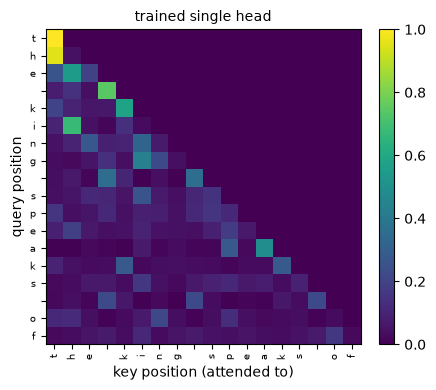

In [11]:
prompt = "the king speaks of"
idx = torch.tensor([tok.encode(prompt)], device=device)
model.eval()
with torch.no_grad():
    _, _, att = model(idx, return_weights=True)

try:
    import matplotlib.pyplot as plt
    cu.show_attention(att[0], tokens=list(prompt), title="trained single head")
    plt.tight_layout(); plt.show()
except ImportError:
    print(att[0])

### How to read that plot

Row `t` = the query at position `t`; bright cells = keys it pulled from.
Everything above the diagonal is black — the causal mask. Look for columns
that are bright across many rows: those are tokens the whole sequence cares
about (spaces and newlines usually, at char level).

In [12]:
with torch.no_grad():
    _, _, att = model(idx, return_weights=True)
a = att[0].cpu()
print("attention entropy per query position (low = focused, high = diffuse):")
for t in range(a.size(0)):
    row = a[t, :t + 1]
    ent = -(row * row.clamp_min(1e-9).log()).sum().item()
    focus = tok.decode([idx[0, int(row.argmax())].item()])
    print(f"  t={t:>2} {prompt[t]!r:>5}  entropy {ent:5.2f}  peak on {focus!r}")

attention entropy per query position (low = focused, high = diffuse):
  t= 0   't'  entropy -0.00  peak on 't'
  t= 1   'h'  entropy  0.19  peak on 't'
  t= 2   'e'  entropy  1.00  peak on 'h'
  t= 3   ' '  entropy  0.82  peak on ' '
  t= 4   'k'  entropy  1.21  peak on 'k'
  t= 5   'i'  entropy  1.08  peak on 'h'
  t= 6   'n'  entropy  1.73  peak on 'i'
  t= 7   'g'  entropy  1.62  peak on 'i'
  t= 8   ' '  entropy  1.55  peak on ' '
  t= 9   's'  entropy  2.13  peak on 'i'
  t=10   'p'  entropy  2.30  peak on 's'
  t=11   'e'  entropy  2.34  peak on 'h'
  t=12   'a'  entropy  1.53  peak on 'a'
  t=13   'k'  entropy  2.12  peak on 'k'
  t=14   's'  entropy  2.57  peak on 'i'
  t=15   ' '  entropy  2.13  peak on ' '
  t=16   'o'  entropy  2.48  peak on 'n'
  t=17   'f'  entropy  2.74  peak on 'o'


## 7 · Self-attention vs cross-attention, causal vs bidirectional

The same four lines cover every variant; only *where Q, K, V come from* and
*what is masked* change:

| variant | Q from | K, V from | mask | used in |
|---|---|---|---|---|
| causal self-attention | x | x | triangular | GPT decoders (nb 04–05) |
| bidirectional self-attention | x | x | padding only | BERT encoders (nb 11) |
| cross-attention | decoder | encoder | padding only | translation (nb 10) |

Bidirectional attention lets every token see every other token — great for
understanding, unusable for generation.

In [13]:
x_enc = torch.randn(1, 5, 16)
bi = SelfAttentionHead(16, 8, 32, causal=False)
_, w_bi = bi(x_enc, return_weights=True)
print("bidirectional row 0 (attends everywhere):", w_bi[0, 0])
_, w_causal = head(x_enc, return_weights=True)
print("causal row 0        (attends to itself):", w_causal[0, 0])

bidirectional row 0 (attends everywhere): tensor([0.166, 0.176, 0.211, 0.211, 0.236], grad_fn=<SelectBackward0>)
causal row 0        (attends to itself): tensor([1., 0., 0., 0., 0.], grad_fn=<SelectBackward0>)


## 8 · Cost

Attention compares every position with every position: `O(T² · d)` time and,
in the naive implementation, an `O(T²)` matrix per head per layer. Doubling
context quadruples the work. This single fact drives most modern
architecture research (flash attention, sliding windows, GQA — notebook 08).

In [14]:
d_model, n_heads, n_layers = 512, 8, 12
for T_ in (128, 512, 2048, 8192):
    scores_per_layer = n_heads * T_ * T_
    mb = scores_per_layer * 4 / 1e6                       # fp32 bytes
    print(f"T={T_:>5}: {scores_per_layer:>12,} score entries/layer "
          f"= {mb:8.1f} MB, {mb * n_layers / 1000:6.2f} GB for {n_layers} layers")

T=  128:      131,072 score entries/layer =      0.5 MB,   0.01 GB for 12 layers
T=  512:    2,097,152 score entries/layer =      8.4 MB,   0.10 GB for 12 layers
T= 2048:   33,554,432 score entries/layer =    134.2 MB,   1.61 GB for 12 layers
T= 8192:  536,870,912 score entries/layer =   2147.5 MB,  25.77 GB for 12 layers


## Exercises

1. **Break causality.** Set `causal=False` in `OneHeadLM` and retrain. The loss
   will collapse toward zero. Explain exactly which tensor leaks the answer.
2. **Remove the scaling.** Delete `* self.head_dim ** -0.5` and retrain with
   `head_dim=64`. Plot the max attention weight per row before and after.
3. **Weights, not values.** Replace `weights @ v` with `weights @ x` (attend
   over raw embeddings, no value projection). How much worse, and why is the
   value projection worth its parameters?
4. **Distance profile.** For the trained head, compute average attention weight
   as a function of `t - j` and plot it. Does the head prefer nearby tokens
   even though it has no positional information? Why might that happen?
5. **Two heads by hand.** Instantiate two `SelfAttentionHead(64, 32, ...)`,
   concatenate their outputs, and confirm you get `(B, T, 64)`. You have just
   written multi-head attention — notebook 04 makes it efficient.

---
**Next:** [04 · Multi-head attention and the transformer block](04_multihead_attention_and_blocks.ipynb)

In [16]:

class OneHeadLM(nn.Module):
    def __init__(self, vocab_size, d_model=64, block_size=32):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.head = SelfAttentionHead(d_model, d_model, block_size, causal=False)
        self.ln = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None, return_weights=False):
        x = self.tok_emb(idx)                                # (B, T, C)
        h = self.head(x, return_weights=return_weights)
        h, att = h if return_weights else (h, None)
        logits = self.out(self.ln(x + h))                    # (B, T, V)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)),
                                   targets.view(-1))
        return (logits, loss, att) if return_weights else (logits, loss)


cu.set_seed(1337)
model = OneHeadLM(tok.vocab_size, 64, block_size)
print("params:", cu.human(cu.count_params(model)))
hist = cu.train(model, splits, steps=800, batch_size=32, block_size=block_size,
                lr=3e-3, device=device, eval_every=200)

params: 20.80K
step     0 | train 4.3298 | val 4.3391 |   0.1s
step   200 | train 2.2871 | val 2.3156 |   1.4s
step   400 | train 2.1480 | val 2.2198 |   2.5s
step   600 | train 2.1212 | val 2.1630 |   3.7s
step   800 | train 2.0689 | val 2.1270 |   4.7s


--- Training Scaled Model ---
Step 0 | Scaled Loss: 4.3502
Step 10 | Scaled Loss: 3.0875
Step 20 | Scaled Loss: 2.1958
Step 30 | Scaled Loss: 1.5316
Step 40 | Scaled Loss: 1.0902

--- Training Unscaled Model ---
Step 0 | Unscaled Loss: 4.3609
Step 10 | Unscaled Loss: 3.0076
Step 20 | Unscaled Loss: 2.3560
Step 30 | Unscaled Loss: 1.9164
Step 40 | Unscaled Loss: 1.6782


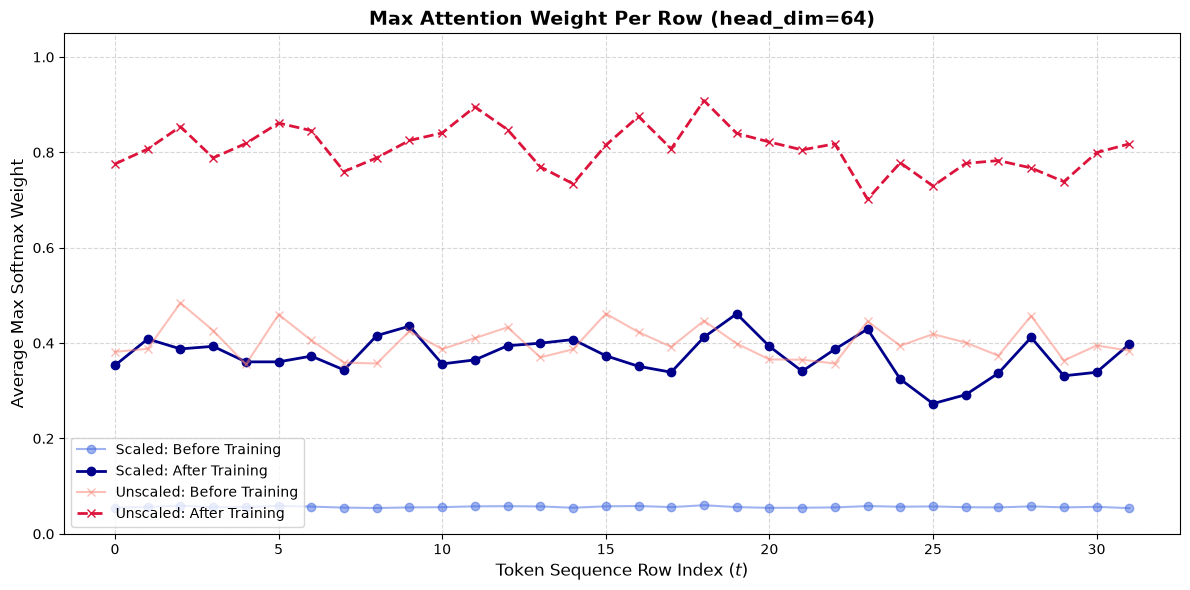

In [21]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

# --- 1. Modified Attention Head from your original code ---
class SelfAttentionHead(nn.Module):
    """Single-head casual/non-causal self-attention: (B, T, C) -> (B, T, head_dim)."""
    def __init__(self, d_model: int, head_dim: int, block_size: int, dropout: float = 0.0, causal: bool = True, scaled: bool = True):
        super().__init__()
        self.key = nn.Linear(d_model, head_dim, bias=False)
        self.query = nn.Linear(d_model, head_dim, bias=False)
        self.value = nn.Linear(d_model, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.causal = causal
        self.head_dim = head_dim
        self.scaled = scaled # <-- Toggle for the scaling factor
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x, return_weights: bool = False):
        B, T, C = x.shape
        q = self.query(x) 
        k = self.key(x)   
        v = self.value(x) 
        
        att = q @ k.transpose(-2, -1) 
        
        # Scale if enabled
        if self.scaled:
            att = att * (self.head_dim ** -0.5) 
            
        if self.causal:
            att = att.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
            
        att = F.softmax(att, dim=-1) 
        out = self.dropout(att) @ v 
        return (out, att) if return_weights else out

# --- 2. Language Model wrapper ---
class OneHeadLM(nn.Module):
    def __init__(self, vocab_size, d_model=64, block_size=32, causal=False, scaled=True):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.head = SelfAttentionHead(d_model, d_model, block_size, causal=causal, scaled=scaled)
        self.ln = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None, return_weights=False):
        x = self.tok_emb(idx) 
        h = self.head(x, return_weights=return_weights)
        h, att = h if return_weights else (h, None)
        logits = self.out(self.ln(x + h)) 
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return (logits, loss, att) if return_weights else (logits, loss)

# --- 3. Setup Dataset ---
torch.manual_seed(1337)
vocab_size, block_size = 65, 32
X_dummy = torch.randint(0, vocab_size, (32, block_size))
Y_dummy = torch.randint(0, vocab_size, (32, block_size))

# --- 4. TRAIN SCALED MODEL ---
print("--- Training Scaled Model ---")
torch.manual_seed(1337) # Keep initialization identical
model_scaled = OneHeadLM(vocab_size, d_model=64, block_size=block_size, causal=False, scaled=True)

with torch.no_grad():
    _, _, att_scaled_before = model_scaled(X_dummy, return_weights=True)

opt_scaled = torch.optim.AdamW(model_scaled.parameters(), lr=0.01)
for step in range(50):
    # FIX: Only unpack 2 items here during training
    logits, loss = model_scaled(X_dummy, Y_dummy) 
    opt_scaled.zero_grad()
    loss.backward()
    opt_scaled.step()
    if step % 10 == 0:
        print(f"Step {step} | Scaled Loss: {loss.item():.4f}")

with torch.no_grad():
    _, _, att_scaled_after = model_scaled(X_dummy, return_weights=True)


# --- 5. TRAIN UNSCALED MODEL ---
print("\n--- Training Unscaled Model ---")
torch.manual_seed(1337) # Keep initialization identical
model_unscaled = OneHeadLM(vocab_size, d_model=64, block_size=block_size, causal=False, scaled=False)

with torch.no_grad():
    _, _, att_unscaled_before = model_unscaled(X_dummy, return_weights=True)

opt_unscaled = torch.optim.AdamW(model_unscaled.parameters(), lr=0.01)
for step in range(50):
    # FIX: Only unpack 2 items here during training
    logits, loss = model_unscaled(X_dummy, Y_dummy) 
    opt_unscaled.zero_grad()
    loss.backward()
    opt_unscaled.step()
    if step % 10 == 0:
        print(f"Step {step} | Unscaled Loss: {loss.item():.4f}")

with torch.no_grad():
    _, _, att_unscaled_after = model_unscaled(X_dummy, return_weights=True)



# --- 6. Process Max Row Probabilities ---
# Added .values to extract the tensor before calculating .mean()
max_scaled_before = att_scaled_before.max(dim=-1).values.mean(dim=0).cpu().numpy()
max_scaled_after = att_scaled_after.max(dim=-1).values.mean(dim=0).cpu().numpy()
max_unscaled_before = att_unscaled_before.max(dim=-1).values.mean(dim=0).cpu().numpy()
max_unscaled_after = att_unscaled_after.max(dim=-1).values.mean(dim=0).cpu().numpy()


# --- 7. Plotting ---
plt.figure(figsize=(12, 6))
token_positions = range(block_size)

# Scaled lines
plt.plot(token_positions, max_scaled_before, marker='o', label='Scaled: Before Training', color='royalblue', alpha=0.5)
plt.plot(token_positions, max_scaled_after, marker='o', label='Scaled: After Training', color='darkblue', linewidth=2)

# Unscaled lines
plt.plot(token_positions, max_unscaled_before, marker='x', label='Unscaled: Before Training', color='salmon', alpha=0.5)
plt.plot(token_positions, max_unscaled_after, marker='x', label='Unscaled: After Training', color='crimson', linewidth=2, linestyle='--')

plt.title('Max Attention Weight Per Row (head_dim=64)', fontsize=14, fontweight='bold')
plt.xlabel('Token Sequence Row Index ($t$)', fontsize=12)
plt.ylabel('Average Max Softmax Weight', fontsize=12)
plt.ylim(0.0, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=10, loc='lower left')

plt.tight_layout()
plt.show()


In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- 1. Modified Attention Head from your original code ---
class SelfAttentionHead(nn.Module):
    """Single-head causal self-attention: (B, T, C) -> (B, T, head_dim)."""
    def __init__(self, d_model: int, head_dim: int, block_size: int, dropout: float = 0.0, causal: bool = True, use_value_proj: bool = True):
        super().__init__()
        self.key = nn.Linear(d_model, head_dim, bias=False)
        self.query = nn.Linear(d_model, head_dim, bias=False)
        self.value = nn.Linear(d_model, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.causal = causal
        self.head_dim = head_dim
        self.use_value_proj = use_value_proj 
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x, return_weights: bool = False):
        B, T, C = x.shape
        q = self.query(x) 
        k = self.key(x)   
        
        # ------------------------------------------------------------------------
        # WHY THE VALUE PROJECTION IS WORTH ITS PARAMETERS (INLINE EXPLANATION)
        # ------------------------------------------------------------------------
        # 1. DECOUPLING ROUTING FROM CONTENT:
        #    - Query & Key determine WHERE information should look (addressing).
        #    - Value determines WHAT semantic message should be sent (content).
        #    - Without W_v, the data transferred is stuck as the literal, raw token 
        #      embedding. The model cannot transform a token's meaning based on context.
        #
        # 2. RESOLVING POLYSEMY (CONTEXTUAL MEANINGS):
        #    - A raw embedding 'x' for the word "bank" is a static vector.
        #    - If it's near "river", attention routes it. If we use 'v = x', we add the 
        #      static "bank" vector to the river context.
        #    - With 'v = W_v(x)', the model can project "bank" into a temporary 
        #      "geographical feature" subspace, altering the vector before transmission.
        #
        # 3. PROTECTING THE RESIDUAL STREAM:
        #    - The residual stream (x + h) is additive space. Adding raw embeddings directly
        #      onto other raw embeddings (att @ x) creates severe geometric distortion
        #      over multiple layers. W_v acts as a linear transform buffer.
        # ------------------------------------------------------------------------
        if self.use_value_proj:
            v = self.value(x) # (B, T, head_dim) -> Abstract representation space
        else:
            v = x             # (B, T, d_model)  -> Raw token embedding space
        
        # Calculate standard scaled dot-product attention
        att = q @ k.transpose(-2, -1) * self.head_dim ** -0.5 
        
        if self.causal:
            att = att.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
            
        att = F.softmax(att, dim=-1) 
        
        # Blend the tokens together
        out = self.dropout(att) @ v 
        return (out, att) if return_weights else out

# --- 2. Language Model wrapper ---
class OneHeadLM(nn.Module):
    def __init__(self, vocab_size, d_model=64, block_size=32, causal=True, use_value_proj=True):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.head = SelfAttentionHead(d_model, d_model, block_size, causal=causal, use_value_proj=use_value_proj)
        self.ln = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, vocab_size)

    def forward(self, idx, targets=None, return_weights=False):
        x = self.tok_emb(idx) 
        h = self.head(x, return_weights=return_weights)
        h, att = h if return_weights else (h, None)
        logits = self.out(self.ln(x + h)) 
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return (logits, loss, att) if return_weights else (logits, loss)

# --- 3. Setup Dataset Simulation (Causal=True) ---
torch.manual_seed(1337)
vocab_size, block_size = 65, 32
X_dummy = torch.randint(0, vocab_size, (32, block_size))
Y_dummy = torch.randint(0, vocab_size, (32, block_size))

# --- 4. TRAIN STANDARD MODEL (WITH VALUE PROJECTION) ---
print("--- Training WITH Value Projection (Standard) ---")
torch.manual_seed(1337)
model_with_v = OneHeadLM(vocab_size, d_model=64, block_size=block_size, causal=True, use_value_proj=True)

opt_with_v = torch.optim.AdamW(model_with_v.parameters(), lr=0.01)
for step in range(100):
    logits, loss = model_with_v(X_dummy, Y_dummy) 
    opt_with_v.zero_grad()
    loss.backward()
    opt_with_v.step()
    if step % 20 == 0 or step == 99:
        print(f"Step {step:2d} | Loss: {loss.item():.4f}")

# --- 5. TRAIN EXPERIMENTAL MODEL (WITHOUT VALUE PROJECTION) ---
# ------------------------------------------------------------------------
# NOTE: Without W_v, when scaling up to Multi-Head Attention, every single 
# head would be forced to extract the identical vector layout 'x'. 
# W_v allows each head to look at different parts of a token's identity.
# ------------------------------------------------------------------------
print("\n--- Training WITHOUT Value Projection (att @ x) ---")
torch.manual_seed(1337)
model_no_v = OneHeadLM(vocab_size, d_model=64, block_size=block_size, causal=True, use_value_proj=False)

opt_no_v = torch.optim.AdamW(model_no_v.parameters(), lr=0.01)
for step in range(100):
    logits, loss = model_no_v(X_dummy, Y_dummy) 
    opt_no_v.zero_grad()
    loss.backward()
    opt_no_v.step()
    if step % 20 == 0 or step == 99:
        print(f"Step {step:2d} | Loss: {loss.item():.4f}")


--- Training WITH Value Projection (Standard) ---
Step  0 | Loss: 4.3513
Step 20 | Loss: 1.9955
Step 40 | Loss: 0.8813
Step 60 | Loss: 0.4431
Step 80 | Loss: 0.2750
Step 99 | Loss: 0.2040

--- Training WITHOUT Value Projection (att @ x) ---
Step  0 | Loss: 4.3435
Step 20 | Loss: 2.4608
Step 40 | Loss: 1.6753
Step 60 | Loss: 1.3355
Step 80 | Loss: 1.1341
Step 99 | Loss: 1.0120


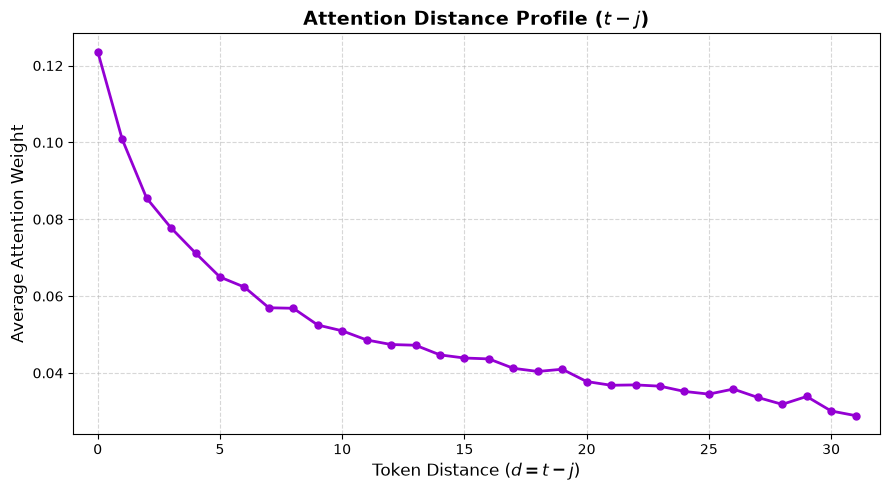

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt

# Using your exact core architecture
class SelfAttentionHead(nn.Module):
    def __init__(self, d_model: int, head_dim: int, block_size: int, causal: bool = True):
        super().__init__()
        self.key = nn.Linear(d_model, head_dim, bias=False)
        self.query = nn.Linear(d_model, head_dim, bias=False)
        self.value = nn.Linear(d_model, head_dim, bias=False)
        self.head_dim = head_dim
        self.causal = causal
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        att = q @ k.transpose(-2, -1) * (self.head_dim ** -0.5)
        if self.causal:
            att = att.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        return att

# 1. Initialize variables (using your dimensions)
torch.manual_seed(1337)
B, T, C = 32, 32, 64 # Batch, Sequence Length, Embedding Dim
x_dummy = torch.randn(B, T, C)

head = SelfAttentionHead(d_model=C, head_dim=C, block_size=T, causal=True)

# 2. Extract attention matrices 
with torch.no_grad():
    att_matrix = head(x_dummy) # Shape: (B, T, T)

# 3. Calculate Average Attention as a function of distance (t - j)
# Distance ranges from 0 (self-attention) up to T-1 (first token vs last token)
distance_accumulators = {d: [] for d in range(T)}

for b in range(B):
    for t in range(T):
        for j in range(t + 1): # Causal boundaries only
            d = t - j
            distance_accumulators[d].append(att_matrix[b, t, j].item())

# Average the values for each distance
distances = sorted(distance_accumulators.keys())
avg_weights = [np.mean(distance_accumulators[d]) for d in distances]

# 4. Generate the Distance Profile Plot
plt.figure(figsize=(9, 5))
plt.plot(distances, avg_weights, marker='o', color='darkviolet', linewidth=2, markersize=5)
plt.title('Attention Distance Profile ($t - j$)', fontsize=14, fontweight='bold')
plt.xlabel('Token Distance ($d = t - j$)', fontsize=12)
plt.ylabel('Average Attention Weight', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlim(-1, T)
plt.tight_layout()
plt.show()


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# --- 1. Your core Attention Head definition ---
class SelfAttentionHead(nn.Module):
    """Single-head causal self-attention: (B, T, C) -> (B, T, head_dim)."""
    def __init__(self, d_model: int, head_dim: int, block_size: int, dropout: float = 0.0, causal: bool = True):
        super().__init__()
        self.key = nn.Linear(d_model, head_dim, bias=False)
        self.query = nn.Linear(d_model, head_dim, bias=False)
        self.value = nn.Linear(d_model, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        self.causal = causal
        self.head_dim = head_dim
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)
        
        att = q @ k.transpose(-2, -1) * (self.head_dim ** -0.5)
        if self.causal:
            att = att.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        att = F.softmax(att, dim=-1)
        
        out = self.dropout(att) @ v
        return out

# --- 2. The Multi-Head Attention nn.Module wrapper ---
class TwoHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int, block_size: int):
        super().__init__()
        # Calculate the size of each head subspace (64 // 2 = 32)
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"
        head_dim = d_model // num_heads
        
        # We use nn.ModuleList so PyTorch tracks parameters of both heads automatically
        self.heads = nn.ModuleList([
            SelfAttentionHead(d_model, head_dim, block_size) for _ in range(num_heads)
        ])
        
        # A final linear projection layer (standard practice in Transformer blocks)
        self.proj = nn.Linear(d_model, d_model)

    def forward(self, x):
        # 1. Pass input x through each head independently
        # 2. Concatenate the outputs along the channel dimension (dim=-1)
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        
        # 3. Pass through the final projection layer
        return self.proj(out)

# --- 3. Verify it Works ---
B, T, C = 2, 8, 64  # Batch size 2, Sequence length 8, d_model 64
x = torch.randn(B, T, C)

# Instantiate our custom 2-head block
multi_head_layer = TwoHeadAttention(d_model=C, num_heads=2, block_size=32)
output = multi_head_layer(x)

print(f"Input Shape:  {tuple(x.shape)}")
print(f"Output Shape: {tuple(output.shape)}")

# Confirm everything acts correctly
assert output.shape == (B, T, 64), "Output dimensions are incorrect!"
print("\n🎉 Success! Enclosed within an nn.Module container.")
